In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

Install Required Packages

In [2]:
!pip install seqeval --quiet
!pip install transformers datasets --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


Imports

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForTokenClassification, TrainingArguments, Trainer
from seqeval.metrics import accuracy_score, precision_score, recall_score, f1_score

Check GPU

In [4]:
# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


Load Dataset

In [6]:
from datasets import load_dataset

# Use the hub repository version
dataset = load_dataset("lhoestq/conll2003")

# Inspect
print(dataset)
print("Columns:", dataset["train"].column_names)

dataset_infos.json: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/1.07M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/281k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
Columns: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags']


Extract NER Labels

In [8]:
# Standard CoNLL-2003 labels
label_list = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 
              'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
num_labels = len(label_list)

print("NER Labels:", label_list)

NER Labels: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


Load BERT Tokenizer and Model

In [9]:
from transformers import AutoTokenizer, AutoModelForTokenClassification

model_name = "bert-base-cased"

# Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Model
model = AutoModelForTokenClassification.from_pretrained(
    model_name,
    num_labels=num_labels,
    id2label={i: label for i, label in enumerate(label_list)},
    label2id={label: i for i, label in enumerate(label_list)}
)

# Move model to GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)
print("Using device:", device)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertForTokenClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized beca

Using device: cuda


Tokenize and Align Labels

In [10]:
def tokenize_and_align_labels(examples):
    tokenized_inputs = tokenizer(
        examples["tokens"],
        truncation=True,
        is_split_into_words=True,
        padding="max_length",
        max_length=128
    )
    
    labels = []
    for i, label in enumerate(examples["ner_tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)
        previous_word_idx = None
        label_ids = []
        for word_idx in word_ids:
            if word_idx is None:
                label_ids.append(-100)
            elif word_idx != previous_word_idx:
                label_ids.append(label[word_idx])
            else:
                label_ids.append(-100)
            previous_word_idx = word_idx
        labels.append(label_ids)
    
    tokenized_inputs["labels"] = labels
    return tokenized_inputs

# Apply to dataset
tokenized_dataset = dataset.map(tokenize_and_align_labels, batched=True)

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

Define Metrics

In [11]:
from seqeval.metrics import accuracy_score, precision_score, recall_score, f1_score

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=2)

    true_predictions = [
        [label_list[p] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]
    true_labels = [
        [label_list[l] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]

    return {
        "precision": precision_score(true_labels, true_predictions),
        "recall": recall_score(true_labels, true_predictions),
        "f1": f1_score(true_labels, true_predictions),
        "accuracy": accuracy_score(true_labels, true_predictions),
    }

Set Training Arguments

In [13]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./bert-ner",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=50,
    eval_strategy="epoch",        # older version argument
    save_strategy="epoch",        # save every epoch
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True
)

Create the Trainer

In [14]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    compute_metrics=compute_metrics
)

Train the model

In [15]:
trainer.train()

/usr/local/lib/python3.12/dist-packages/torch/nn/parallel/_functions.py:71: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn(


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.106416,0.090083,0.919036,0.931267,0.925111,0.987725
2,0.065507,0.079122,0.936810,0.944070,0.940426,0.989810
3,0.033990,0.075533,0.941501,0.948956,0.945214,0.990686


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/nn/parallel/_functions.py:71: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/nn/parallel/_functions.py:71: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

TrainOutput(global_step=1317, training_loss=0.13424864517710114, metrics={'train_runtime': 659.6719, 'train_samples_per_second': 63.854, 'train_steps_per_second': 1.996, 'total_flos': 2751824963545344.0, 'train_loss': 0.13424864517710114, 'epoch': 3.0})

Evaluate on the test set

In [16]:
test_results = trainer.evaluate(tokenized_dataset["test"])

print("Test set performance:")
print(f"Precision: {test_results['eval_precision']:.4f}")
print(f"Recall:    {test_results['eval_recall']:.4f}")
print(f"F1-score:  {test_results['eval_f1']:.4f}")
print(f"Accuracy:  {test_results['eval_accuracy']:.4f}")

/usr/local/lib/python3.12/dist-packages/torch/nn/parallel/_functions.py:71: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  warnings.warn(


Test set performance:
Precision: 0.9021
Recall:    0.9148
F1-score:  0.9084
Accuracy:  0.9822


Plot Training Loss

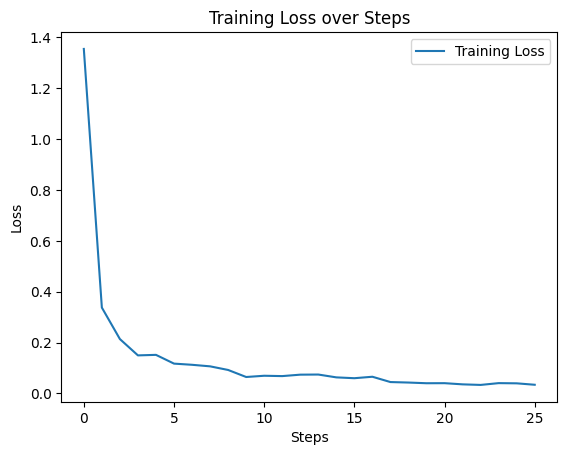

In [18]:
# Extract loss values from trainer logs
loss_values = [x["loss"] for x in trainer.state.log_history if "loss" in x]

# Plot only the loss
plt.plot(loss_values, label="Training Loss")
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("Training Loss over Steps")
plt.legend()
plt.show()

Evaluate on Test Set

In [19]:
# Evaluate on the test dataset
test_results = trainer.evaluate(tokenized_dataset["test"])

# Print results
print("Test set performance:")
print(f"Precision: {test_results['eval_precision']:.4f}")
print(f"Recall:    {test_results['eval_recall']:.4f}")
print(f"F1-score:  {test_results['eval_f1']:.4f}")
print(f"Accuracy:  {test_results['eval_accuracy']:.4f}")

Test set performance:
Precision: 0.9021
Recall:    0.9148
F1-score:  0.9084
Accuracy:  0.9822


Make Predictions on a Few Samples

In [20]:
# Select a few examples from the test set
sample_texts = dataset["test"][:3]["tokens"]

# Tokenize
inputs = tokenizer(sample_texts, is_split_into_words=True, return_tensors="pt", padding=True, truncation=True)
inputs = {k: v.to(trainer.model.device) for k, v in inputs.items()}

# Get model predictions
with torch.no_grad():
    outputs = trainer.model(**inputs)
predictions = torch.argmax(outputs.logits, dim=-1).cpu().numpy()

# Decode predictions to labels
for i, sample in enumerate(sample_texts):
    pred_labels = [label_list[p] for p in predictions[i][:len(sample)]]
    print(f"Sentence {i+1}:")
    print("Tokens: ", sample)
    print("Predicted NER tags:", pred_labels)
    print()

Sentence 1:
Tokens:  ['SOCCER', '-', 'JAPAN', 'GET', 'LUCKY', 'WIN', ',', 'CHINA', 'IN', 'SURPRISE', 'DEFEAT', '.']
Predicted NER tags: ['O', 'O', 'O', 'O', 'O', 'O', 'B-PER', 'B-PER', 'B-PER', 'O', 'O', 'B-LOC']

Sentence 2:
Tokens:  ['Nadim', 'Ladki']
Predicted NER tags: ['O', 'B-PER']

Sentence 3:
Tokens:  ['AL-AIN', ',', 'United', 'Arab', 'Emirates', '1996-12-06']
Predicted NER tags: ['O', 'B-LOC', 'I-LOC', 'I-LOC', 'I-LOC', 'O']



Confusion Matrix / Classification Report

In [23]:
from sklearn.metrics import classification_report, confusion_matrix

# Predictions already tokenized and aligned
preds = predictions  # shape: (num_sentences, max_length)
true_labels = tokenized_dataset["test"]["labels"]  # shape: same as preds

# Flatten only non-padding tokens (-100)
true_labels_flat = []
pred_labels_flat = []

for pred_seq, true_seq in zip(preds, true_labels):
    for p, t in zip(pred_seq, true_seq):
        if t != -100:  # ignore padding
            true_labels_flat.append(label_list[t])
            pred_labels_flat.append(label_list[p])

# Check lengths
print("Length of true_labels_flat:", len(true_labels_flat))
print("Length of pred_labels_flat:", len(pred_labels_flat))

# Classification report
print(classification_report(true_labels_flat, pred_labels_flat))

# Confusion matrix
cm = confusion_matrix(true_labels_flat, pred_labels_flat, labels=label_list)
print(cm)

Length of true_labels_flat: 20
Length of pred_labels_flat: 20
              precision    recall  f1-score   support

       B-LOC       0.67      0.67      0.67         3
       B-PER       0.67      1.00      0.80         2
       I-LOC       1.00      1.00      1.00         2
       I-PER       1.00      1.00      1.00         1
           O       1.00      0.92      0.96        12

    accuracy                           0.90        20
   macro avg       0.87      0.92      0.88        20
weighted avg       0.92      0.90      0.90        20

[[11  0  0  0  0  1  0  0  0]
 [ 0  2  0  0  0  0  0  0  0]
 [ 0  0  1  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0]
 [ 0  1  0  0  0  2  0  0  0]
 [ 0  0  0  0  0  0  2  0  0]
 [ 0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0]]
